# Laboratorio 10: Búsqueda por Similitud

Dataset: **Dry Bean** (UCI id=602), 13 611 granos con 16 atributos numéricos y 7 clases.

## Configuración y Carga de Datos

```sql
CREATE EXTENSION IF NOT EXISTS cube;

CREATE TABLE dry_beans (
    id SERIAL PRIMARY KEY,
    features_seq cube,
    features_idx cube
);

CREATE INDEX dry_beans_features_idx_gist ON dry_beans USING gist (features_idx);
```

> La extensión, la tabla y el índice se crean al hacer `docker compose up` (ver `init.sql`). Los datos se cargan desde la celda siguiente.

La fila `i` del DataFrame (0-based) corresponde a `id = i + 1` en `dry_beans`.

In [3]:
import os
import pandas as pd

DATA_PATH = "data/Dry_Bean_Dataset.xlsx"

if os.path.exists(DATA_PATH):
    df = pd.read_excel(DATA_PATH)
else:
    from ucimlrepo import fetch_ucirepo
    dry_bean = fetch_ucirepo(id=602)
    X = dry_bean.data.features
    y = dry_bean.data.targets
    df = pd.concat([X, y], axis=1)
    os.makedirs("data", exist_ok=True)
    df.to_csv(DATA_PATH, index=False)

FEATURES = list(df.columns[:16])
TARGET = df.columns[16]

print(f"Filas: {len(df)}, atributos: {len(FEATURES)}, clases: {df[TARGET].nunique()}")
df.head()

Filas: 13611, atributos: 16, clases: 7


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [ ]:
import psycopg2
from psycopg2.extras import execute_values


def connect_db():
    conn = psycopg2.connect(
        dbname="postgres", user="postgres",
        password="postgres", host="localhost", port=os.getenv("PGPORT", "5432")
    )
    return conn


conn = connect_db()
with conn.cursor() as cur:
    cur.execute("SELECT COUNT(*) FROM dry_beans;")
    if cur.fetchone()[0] == 0:
        cur.execute("SELECT setval(pg_get_serial_sequence('dry_beans', 'id'), 1, false);")
        rows = [(vec, vec) for vec in df[FEATURES].astype(float).values.tolist()]
        execute_values(cur,
                       "INSERT INTO dry_beans (features_seq, features_idx) VALUES %s;",
                       rows, template="(cube(%s::float8[]), cube(%s::float8[]))", page_size=1000)
        conn.commit()
        print(f"Insertadas {len(rows)} filas en dry_beans")
    else:
        print("dry_beans ya tiene datos, no se inserta nada")
    cur.execute("SELECT COUNT(*) FROM dry_beans;")
    print(f"Filas en dry_beans: {cur.fetchone()[0]}")
conn.close()

Insertadas 13611 filas en dry_beans
Filas en dry_beans: 13611


## Tratamiento de Datos

Cada grano se representa con un vector de características $x \in \mathbb{R}^{16}$: toda consulta trabaja solo con esta abstracción y no con la imagen original. La similitud se mide con la distancia euclidiana:

$$d(x, y) = \sqrt{\sum_{i=1}^{D} |x_i - y_i|^2}$$

La distancia euclidiana considera magnitud, escala y diferencias absolutas. Si un atributo tiene valores mucho más grandes que los demás, domina la distancia y el resto deja de influir. Antes de buscar hay que revisar:

1. Calidad de los datos: tipos, valores nulos y duplicados.
2. Escala de cada atributo y su aporte a la distancia.
3. Normalización para que los 16 atributos aporten por igual.

### 1. Calidad de los datos

In [10]:
print("Tipos de datos:")
print(df[FEATURES].dtypes.value_counts().to_string())
print(f"\nValores nulos: {df.isna().sum().sum()}")
print(f"Filas duplicadas (mismo vector y clase): {df.duplicated().sum()}")
print("\nGranos por clase:")
print(df[TARGET].value_counts().to_string())

Tipos de datos:
float64    14
int64       2

Valores nulos: 0
Filas duplicadas (mismo vector y clase): 68

Granos por clase:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522


- Los 16 atributos son numéricos y no hay nulos, así que no se necesita imputación.
- Las filas duplicadas **no se eliminan**: borrarlas cambiaría los índices y `Q15`, `Q2166` y `Q4768` ya no serían los mismos objetos (ni coincidirían con los `id` de PostgreSQL en P3). En las búsquedas aparecerán a distancia 0 de su copia, lo cual es correcto.
- Las clases están desbalanceadas (DERMASON ≈ 26 %, BOMBAY ≈ 4 %). Esto influye en la precisión: con radios grandes la precisión tiende a la proporción de la clase de la consulta.

### 2. Escala de los atributos

Para dos objetos aleatorios $x, y$ se cumple $E[(x_i - y_i)^2] = 2\,\mathrm{Var}(x_i)$, por lo que el aporte de cada atributo a la distancia euclidiana al cuadrado es proporcional a su varianza.

In [11]:
import numpy as np

X_raw = df[FEATURES].to_numpy(dtype=float)
y = df[TARGET].to_numpy()

var_raw = X_raw.var(axis=0)
escala = pd.DataFrame({
    "min": X_raw.min(axis=0),
    "max": X_raw.max(axis=0),
    "desv. estándar": X_raw.std(axis=0),
    "aporte a d² (%)": var_raw / var_raw.sum() * 100,
}, index=FEATURES).sort_values("aporte a d² (%)", ascending=False)

escala.style.format({"min": "{:.4f}", "max": "{:.4f}", "desv. estándar": "{:.4f}", "aporte a d² (%)": "{:.4f}"})

,min,max,desv. estándar,aporte a d² (%)
ConvexArea,20684.0000,263261.0000,29773.8220,50.7611
Area,20420.0000,254616.0000,29323.0185,49.2356
Perimeter,524.7360,1985.3700,214.2818,0.0026
MajorAxisLength,183.6012,738.8602,85.6910,0.0004
EquivDiameter,161.2438,569.3744,59.1749,0.0002
MinorAxisLength,122.5127,460.1985,44.9684,0.0001
AspectRation,1.0249,2.4303,0.2467,0.0000
ShapeFactor3,0.4103,0.9748,0.0990,0.0000
Eccentricity,0.2190,0.9114,0.0920,0.0000
Compactness,0.6406,0.9873,0.0617,0.0000


Sin normalizar, `ConvexArea` y `Area` (valores del orden de $10^4$–$10^5$) concentran casi el 100 % de la distancia, mientras que atributos como `roundness`, `Solidity` o los `ShapeFactor` (valores entre 0 y 1) no aportan nada. La búsqueda solo compararía el tamaño del grano e ignoraría su forma, que es lo que distingue a varias clases.

### 3. Normalización z-score

Se estandariza cada atributo con su media y desviación estándar:

$$x'_i = \frac{x_i - \mu_i}{\sigma_i}$$

Así cada atributo queda con media 0 y desviación 1, y todos aportan lo mismo a la distancia (1/16 = 6.25 %). Se prefiere z-score sobre min-max porque es menos sensible a valores extremos: min-max depende solo del mínimo y del máximo de cada atributo.

In [12]:
mu = X_raw.mean(axis=0)
sigma = X_raw.std(axis=0)
X = (X_raw - mu) / sigma

var_norm = X.var(axis=0)
pd.DataFrame({
    "media": X.mean(axis=0),
    "desv. estándar": X.std(axis=0),
    "aporte a d² (%)": var_norm / var_norm.sum() * 100,
}, index=FEATURES).round(4)

,media,desv. estándar,aporte a d² (%)
Area,0.0,1.0,6.25
Perimeter,-0.0,1.0,6.25
MajorAxisLength,-0.0,1.0,6.25
MinorAxisLength,0.0,1.0,6.25
AspectRation,0.0,1.0,6.25
Eccentricity,-0.0,1.0,6.25
ConvexArea,0.0,1.0,6.25
EquivDiameter,-0.0,1.0,6.25
Extent,-0.0,1.0,6.25
Solidity,0.0,1.0,6.25


### Objetos de consulta

Se mantiene la convención de la carga: la fila `i` del DataFrame corresponde a `id = i + 1`, así que $Q_{15}$ es la fila 14.

In [13]:
QUERY_IDS = [15, 2166, 4768]
QUERY_ROWS = {qid: qid - 1 for qid in QUERY_IDS}

pd.DataFrame({
    "id": QUERY_IDS,
    "fila": [QUERY_ROWS[q] for q in QUERY_IDS],
    "clase": [y[QUERY_ROWS[q]] for q in QUERY_IDS],
})

,id,fila,clase
0,15,14,SEKER
1,2166,2165,BARBUNYA
2,4768,4767,CALI


## P1a

### a) Análisis de la distribución de la distancia

El problema de la consulta por rango es elegir el radio de tolerancia $r$: si es muy pequeño no retorna nada y si es muy grande retorna demasiado. Para elegirlo con criterio se estima la distribución de distancias de la colección calculando la distancia euclidiana entre **5000 pares de objetos aleatorios** (sobre los vectores normalizados).

In [14]:
import matplotlib.pyplot as plt


def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))


N_PAIRS = 5000
rng = np.random.default_rng(42)

pairs = []
while len(pairs) < N_PAIRS:
    i, j = rng.integers(0, len(X), size=2)
    if i != j:
        pairs.append((i, j))

dists = np.array([euclidean(X[i], X[j]) for i, j in pairs])
pd.Series(dists, name="distancia").describe(percentiles=[.01, .02, .05, .10, .20, .50, .90]).round(3)

count    5000.000
mean        5.018
std         2.703
min         0.352
1%          0.958
2%          1.174
5%          1.556
10%         2.023
20%         2.734
50%         4.578
90%         8.559
max        20.530
Name: distancia, dtype: float64

Los radios se toman de **percentiles bajos** de la distribución: el percentil $p$ indica que un $p\,\%$ de los pares aleatorios están a esa distancia o menos, así que un radio en el percentil 1 cubre aproximadamente al 1 % de la colección. Percentiles altos (p. ej. la mediana) cubrirían a la mitad de la colección y la búsqueda dejaría de ser selectiva.

In [15]:
PERCENTILES = [1, 2, 5, 10, 20]
RADII = np.percentile(dists, PERCENTILES)

pd.DataFrame({
    "radio": [f"r{k}" for k in range(1, 6)],
    "percentil": PERCENTILES,
    "valor": RADII.round(4),
})

,radio,percentil,valor
0,r1,1,0.9577
1,r2,2,1.1743
2,r3,5,1.5561
3,r4,10,2.0234
4,r5,20,2.7337


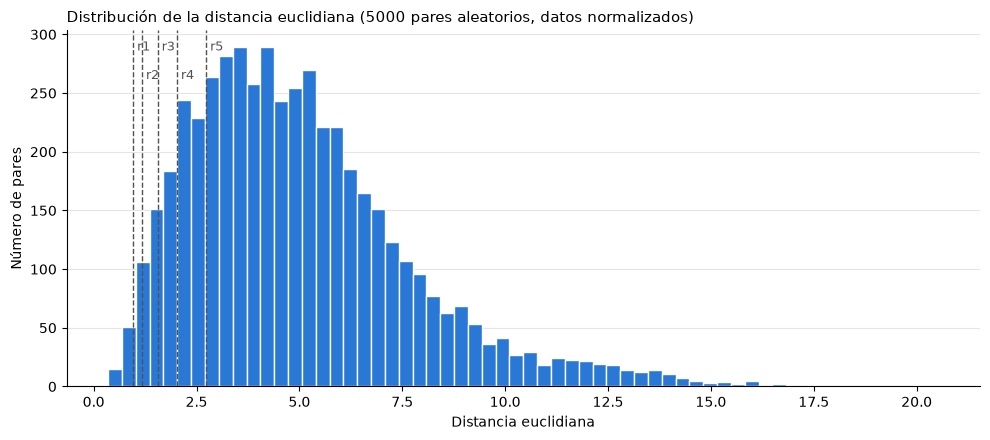

In [16]:
os.makedirs("results", exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(dists, bins=60, color="#2a78d6", edgecolor="#fcfcfb", linewidth=1)
for k, r in enumerate(RADII, start=1):
    ax.axvline(r, color="#52514e", linestyle="--", linewidth=1)
    ax.text(r, ax.get_ylim()[1] * (0.97 if k % 2 else 0.89), f" r{k}", color="#52514e", fontsize=9, va="top")

ax.set_title(f"Distribución de la distancia euclidiana ({N_PAIRS} pares aleatorios, datos normalizados)",
             loc="left", fontsize=11)
ax.set_xlabel("Distancia euclidiana")
ax.set_ylabel("Número de pares")
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

fig.tight_layout()
fig.savefig("results/p1_distribucion.png", dpi=150)
plt.show()

## P1b

### b) Algoritmo de Búsqueda por Rango

Dado un objeto de consulta $q$ y un radio de tolerancia $r \in \mathbb{R}^+$, la consulta por rango retorna todos los objetos de la colección dentro de la **bola de consulta**:

$$(q, r) = \{u \in \mathbb{U} : \delta(u, q) \le r\}$$

El algoritmo lineal recorre toda la colección, calcula $\delta(u, q)$ con la distancia euclidiana y conserva los objetos con $\delta(u, q) \le r$. El objeto de consulta se retira de la colección antes de buscar (si no, siempre aparecería a distancia 0). El costo es $O(n \cdot D)$: una distancia de costo $O(D)$ por cada uno de los $n$ objetos.

La efectividad se mide con la **precisión**: de los objetos recuperados, cuántos pertenecen a la misma clase que la consulta.

$$PR = \frac{\#ObjetosRelevantesRecuperados}{\#ObjetosRecuperados} = \frac{TP}{TP + FP}$$

In [18]:
def range_search(X, q_row, r):
    q = X[q_row]
    result = []
    for i in range(len(X)):
        if i == q_row:  
            continue
        d = euclidean(X[i], q)
        if d <= r:
            result.append((i, d))
    result.sort(key=lambda t: t[1])
    return result


def precision(result, q_class):
    if not result:
        return float("nan")
    relevantes = sum(1 for i, _ in result if y[i] == q_class)
    return relevantes / len(result)

In [19]:
pr_table = pd.DataFrame(index=[f"r{k} = {r:.4f}" for k, r in enumerate(RADII, start=1)],
                        columns=[f"Q{q}" for q in QUERY_IDS], dtype=float)
n_table = pr_table.copy()

for qid in QUERY_IDS:
    q_row = QUERY_ROWS[qid]
    for k, r in enumerate(RADII):
        result = range_search(X, q_row, r)
        pr_table.iloc[k, QUERY_IDS.index(qid)] = precision(result, y[q_row])
        n_table.iloc[k, QUERY_IDS.index(qid)] = len(result)

pr_table.to_csv("results/p1_precision.csv")
n_table.astype(int).to_csv("results/p1_recuperados.csv")

print("Precisión (PR):")
display(pr_table.round(4))
print("Objetos recuperados:")
display(n_table.astype(int))

Precisión (PR):


,Q15,Q2166,Q4768
r1 = 0.9577,1.0000,1.0000,1.0000
r2 = 1.1743,1.0000,1.0000,1.0000
r3 = 1.5561,0.9969,0.9327,0.9896
r4 = 2.0234,0.9909,0.7851,0.9055
r5 = 2.7337,0.9834,0.4051,0.7228


Objetos recuperados:


,Q15,Q2166,Q4768
r1 = 0.9577,89,5,13
r2 = 1.1743,156,22,25
r3 = 1.5561,321,104,96
r4 = 2.0234,660,335,307
r5 = 2.7337,1208,1671,1093


Ejemplo: los 10 objetos más cercanos recuperados para $Q_{15}$ con el radio $r_1$.

In [20]:
q_row = QUERY_ROWS[15]
ejemplo = range_search(X, q_row, RADII[0])[:10]
pd.DataFrame({
    "id": [i + 1 for i, _ in ejemplo],
    "distancia": [round(d, 4) for _, d in ejemplo],
    "clase": [y[i] for i, _ in ejemplo],
    "relevante": [y[i] == y[q_row] for i, _ in ejemplo],
})

,id,distancia,clase,relevante
0,19,0.2903,SEKER,True
1,41,0.3778,SEKER,True
2,122,0.4576,SEKER,True
3,31,0.4698,SEKER,True
4,93,0.4833,SEKER,True
5,16,0.4899,SEKER,True
6,54,0.4950,SEKER,True
7,12,0.5225,SEKER,True
8,184,0.5776,SEKER,True
9,150,0.5776,SEKER,True


### Análisis de resultados

| PR | $Q_{15}$ (SEKER) | $Q_{2166}$ (BARBUNYA) | $Q_{4768}$ (CALI) |
|---|---|---|---|
| r1 = 0.9577 | 1.0000 (89) | 1.0000 (5) | 1.0000 (13) |
| r2 = 1.1743 | 1.0000 (156) | 1.0000 (22) | 1.0000 (25) |
| r3 = 1.5561 | 0.9969 (321) | 0.9327 (104) | 0.9896 (96) |
| r4 = 2.0234 | 0.9909 (660) | 0.7851 (335) | 0.9055 (307) |
| r5 = 2.7337 | 0.9834 (1208) | 0.4051 (1671) | 0.7228 (1093) |

*Entre paréntesis: número de objetos recuperados.*

- **La precisión baja al aumentar el radio.** Con radios pequeños solo entran vecinos muy parecidos y la precisión es 1.0; al crecer la bola de consulta se recuperan más objetos relevantes pero también objetos de otras clases. Es la relación empírica precisión vs. exhaustividad: ganar *recall* cuesta precisión.
- **El número de resultados no se controla.** Con el mismo radio $r_1$, $Q_{15}$ recupera 89 objetos y $Q_{2166}$ solo 5. Es el problema de elegir el radio: un mismo $r$ es "grande" en una zona densa del espacio y "pequeño" en una zona dispersa.
- **$Q_{15}$ (SEKER)** está en una región densa y bien separada: con $r_5$ recupera 1208 objetos con 98 % de precisión (solo 20 DERMASON se cuelan).
- **$Q_{2166}$ (BARBUNYA)** está cerca de la frontera con otras clases: con $r_5$ recupera 677 BARBUNYA pero también 462 SIRA, 315 CALI y 214 HOROZ, y su precisión cae a 0.41.
- **$Q_{4768}$ (CALI)** queda en un punto intermedio: su principal confusión es con HOROZ (228 objetos con $r_5$).
- **Sin normalizar**, la distancia dependería casi solo de `Area` y `ConvexArea` (ver *Tratamiento de Datos*), por lo que la búsqueda compararía solo el tamaño del grano y no su forma.

## P2

El algoritmo KNN recibe un objeto de consulta $q$ y un número entero $k \ge 1$. Retorna los $k$ objetos más cercanos de la colección ordenados por distancia euclidiana.

A diferencia de la búsqueda por rango, KNN asegura devolver exactamente $k$ resultados, independientemente de la densidad de la zona.

Para implementar el algoritmo de forma eficiente, se gestionan los candidatos en un max heap de tamaño $k$)usando la librería `heapq` de Python:
- Mantiene las distancias como números negativos para simular un max heap.
- Si el heap tiene menos de $k$ elementos, se inserta directamente $O(\log k)$.
- Si la distancia al objeto actual es menor que la distancia del elemento más lejano del heap (la raíz `-heap[0][0]`), se reemplaza en $O(\log k)$.

In [ ]:
import heapq

def knn_search(X, q_row, k):
    q = X[q_row]
    max_heap = []  

    for i in range(len(X)):
        if i == q_row:  
            continue
        
        d = euclidean(X[i], q)

        if len(max_heap) < k:
            heapq.heappush(max_heap, (-d, i))
        else:
            # Si la distancia actual es menor que la peor del top-k
            if d < -max_heap[0][0]:
                heapq.heappushpop(max_heap, (-d, i))

    # Extraer los k vecinos y ordenarlos de menor a mayor distancia
    res = [(-d, i) for d, i in max_heap]
    res.sort(key=lambda t: t[0])
    return [(i, d) for d, i in res]


def precision_knn(result, q_class):
    if not result:
        return 0.0
    relevantes = sum(1 for i, _ in result if y[i] == q_class)
    return relevantes / len(result)

k_vals = [2, 4, 8, 16, 32]

knn_pr_table = pd.DataFrame(
    index=[f"k = {k}" for k in k_vals],
    columns=[f"Q{q}" for q in QUERY_IDS],
    dtype=float
)

for qid in QUERY_IDS:
    q_row = QUERY_ROWS[qid]
    q_class = y[q_row]
    
    for k in k_vals:
        result = knn_search(X, q_row, k)
        pr = precision_knn(result, q_class)
        knn_pr_table.loc[f"k = {k}", f"Q{qid}"] = pr

knn_pr_table.to_csv("results/p2_precision_knn.csv")

print("Tabla de Precisión para KNN:")
display(knn_pr_table.round(4))

Tabla de Precisión para KNN:


,Q15,Q2166,Q4768
k = 2,1.0,1.0,1.0
k = 4,1.0,1.0,1.0
k = 8,1.0,1.0,1.0
k = 16,1.0,1.0,1.0
k = 32,1.0,1.0,1.0


### Preguntas de Análisis: Rango vs. KNN

**¿Cuál de los dos métodos de búsqueda usted usaría en un ambiente real de recuperación de la información?**

En un ambiente real de producción/recuperación de información, utilizaríamos KNN por las siguientes razones:

1. Predicibilidad y control en la respuesta: KNN asegrua devolver un tamaño de resultado constante ($k$), lo que facilita la paginación y evita saturar la memoria o la red. En la búsqueda por rango, si se elige un radio $r$ muy grande, se pueden retornar miles de objetos innecesarios; y si $r$ es muy pequeño, se puede retornar la lista vacía.
2. Independencia de la densidad local: En datasets reales, la densidad de puntos varía según la región del espacio vectorial. Calibrar un radio global $r$ para la búsqueda por rango es muy difícil. KNN se adapta automáticamente a la densidad local en torno a la consulta.
3. Puntuación y Ranking: KNN entrega de forma nativa los $k$ mejores candidatos ordenados por relevancia/similitud para ser presentados directamente al usuario.

## P3: KNN

## P3: Escalabilidad

## P3: Dimensionalidad